# inkatoms tutorial

**inkatoms** draws atomic structures (molecules, crystals, surfaces, simulation snapshots)
straight into matplotlib figures. The drawings are vector graphics, so they stay sharp in a
PDF, sit next to your plots in the same figure, and can be edited in Illustrator or Inkscape.

This notebook starts from nothing and builds up. Each section has:

* a short explanation,
* a small example you can run,
* an **interactive** cell with sliders and menus to play with, and
* a **Try it yourself** suggestion.

Run the cells in order with **Shift + Enter**. Nothing here needs your own data; the last
section shows how to use your own files. The sliders and menus only work when the notebook is
running (in Jupyter, VS Code or Google Colab), not in a static preview such as GitHub's.

**Contents**
1. Your first drawing
2. Choosing the view
3. Colours, shading and drawing modes
4. Depth: making a flat picture read in 3D
5. Pointing things out: highlights, labels and measurements
6. Molecules: bond orders and SMILES
7. Crystals: unit cells, polyhedra and planes
8. Colouring atoms by a value
9. Surfaces: cutting out the part you want
10. Building a figure for a paper
11. Trajectories: finding and drawing reactions
12. Comparing two structures
13. Saving, and using your own files

## 0. Setup

If you are running this on your own computer, install inkatoms once in a terminal:

```bash
pip install "inkatoms[all]" ipywidgets
```

On **Google Colab** the next cell installs it for you (this takes a minute the first time).
Just run it; you do not need to read its code.

Under every interactive picture in this notebook, the line of code that draws exactly that
picture is printed, so you can copy it into your own work.

In [1]:
#@title Setup: run this first
import sys

if "google.colab" in sys.modules:                 # Colab: install inkatoms into this session
    get_ipython().run_line_magic("pip", 'install -q "inkatoms[all] @ git+https://github.com/JoelCrewe/InkAtoms" ipywidgets')
    from google.colab import output
    output.enable_custom_widget_manager()

%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from ase import Atoms
from ase.build import molecule, bulk, fcc111, mx2, add_adsorbate
from ipywidgets import interact

try:
    import inkatoms as ia
except ImportError:
    raise ImportError("inkatoms is not installed in this kernel. Pick the kernel of the environment "
                      "where you installed it (Kernel > Change kernel), or run: "
                      '%pip install "inkatoms[all]" ipywidgets') from None

try:                                               # keep RDKit's own error messages quiet
    from rdkit import RDLogger
    RDLogger.DisableLog("rdApp.*")
except ImportError:
    pass


class raw(str):
    """A variable name to print as it is, without quotes."""
    def __repr__(self):
        return str(self)


def print_call(func, *args, **kwargs):
    """Print the call that makes the picture above, leaving out options that are None."""
    def as_code(value):
        return repr(round(value, 3) if isinstance(value, float) else value).replace("'", '"')
    options = [f"{key}={as_code(value)}" for key, value in kwargs.items() if value is not None]
    print(f"{func}({', '.join([*args, *options])})")


plt.rcParams["figure.dpi"] = 110
print("inkatoms", ia.__version__, "is ready")

## 1. Your first drawing

inkatoms draws onto a matplotlib **Axes** (`ax`), the same thing you use for any plot.
The structure comes from [ASE](https://wiki.fysik.dtu.dk/ase/), which can build common
molecules and crystals and read almost any structure file.

Three lines: make a figure, make a molecule, draw it.

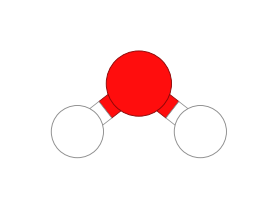

In [2]:
fig, ax = plt.subplots(figsize=(3, 3))
water = molecule("H2O")
ia.draw(ax, water, view="auto")
plt.show()

`ia.draw` found the bonds, chose sizes and colours, and turned the axes off.
`view="auto"` turned the molecule to face you; section 2 explains views.
`molecule(...)` knows about a hundred small molecules by formula, for example
`"CH4"`, `"C6H6"` (benzene), `"CH3CH2OH"` (ethanol) or `"C2H6SO"` (DMSO).

**Try it yourself:** change `"H2O"` to `"C6H6"` and run the cell again.

## 2. Choosing the view

`view` says which direction points **out of the page, towards you**:

| `view=` | what you see |
|---|---|
| `"z"` | a top view: x to the right, y up |
| `"-y"` | a side view: x to the right, z up |
| `"auto"` | turns the structure to show its widest face (good for molecules) |

`rotate="20x,-30y"` then tilts the picture about the page's own axes.
Move the sliders below.

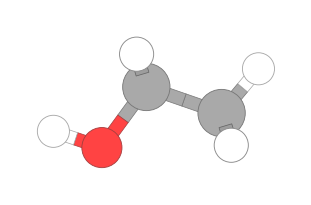

ia.draw(ax, ethanol, view="auto")


interactive(children=(Dropdown(description='view', options=('auto', 'z', '-y', 'x', '-x', 'y', '-z'), value='a…

In [3]:
ethanol = molecule("CH3CH2OH")

@interact(view=["auto", "z", "-y", "x", "-x", "y", "-z"], tilt_x=(-90, 90, 5), tilt_y=(-90, 90, 5))
def show(view="auto", tilt_x=0, tilt_y=0):
    fig, ax = plt.subplots(figsize=(3.4, 3.4))
    ia.draw(ax, ethanol, view=view, rotate=f"{tilt_x}x,{tilt_y}y")
    plt.show()
    print_call("ia.draw", "ax", "ethanol", view=view, rotate=f"{tilt_x}x,{tilt_y}y" if tilt_x or tilt_y else None)

**Try it yourself:** find a view of ethanol where the O–H bond points straight at you.

## 3. Colours, shading and drawing modes

* **`style`** sets the colours. The presets use standard element colours:
  `"jmol"` (the default), `"cpk"`, `"vesta"`, `"colourblind"`, `"greyscale"`,
  `"bw"` (black-and-white line art) and `"dark"` (for slides).
* **`shading`** is `"flat"`, `"glossy"` or `"soft"`. All three stay vector graphics.
* **`mode`** is `"ballstick"`, `"spacefill"` or `"sticks"`.

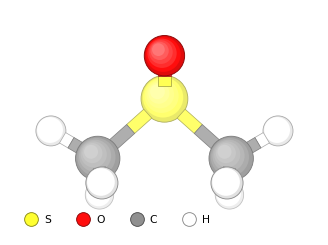

ia.draw(ax, molecule("C2H6SO"), view="auto", rotate="25x", style="jmol", shading="soft", mode="ballstick")


interactive(children=(Dropdown(description='molecule_name', options=('DMSO (S, O)', 'thiophene', 'acetic acid'…

In [4]:
molecules = {"DMSO (S, O)": "C2H6SO", "thiophene": "C4H4S", "acetic acid": "CH3COOH",
             "pyridine (N)": "C5H5N", "benzene": "C6H6"}

@interact(molecule_name=list(molecules), style=["jmol", "cpk", "vesta", "colourblind", "greyscale", "bw"],
          shading=["flat", "glossy", "soft"], mode=["ballstick", "spacefill", "sticks"])
def show(molecule_name="DMSO (S, O)", style="jmol", shading="soft", mode="ballstick"):
    mol = molecule(molecules[molecule_name])
    fig, ax = plt.subplots(figsize=(3.6, 3.2))
    art = ia.draw(ax, mol, view="auto", rotate="25x", style=style, shading=shading, mode=mode)
    ia.legend(ax, art, loc="lower left", fontsize=7, ncol=4)
    plt.show()
    print_call("ia.draw", "ax", f'molecule("{molecules[molecule_name]}")', view="auto", rotate="25x",
               style=style, shading=shading, mode=mode)

You can also change any single detail, for example one element's colour:

```python
ia.draw(ax, mol, colors={"S": "gold"}, bond_color="grey", ball_scale=0.3)
```

**Try it yourself:** draw DMSO with `style="bw"` and `shading="flat"`. That is what a
black-and-white printed figure would look like.

## 4. Depth: making a flat picture read in 3D

A drawing on paper is flat, so inkatoms **fades and slightly shrinks atoms that are further
away** ("depth cueing"). It is on by default. Below is a tilted MoS₂ sheet: move the sliders
to see what each setting does, or untick `depth_cue` to switch it off completely (some figures
read better without it).

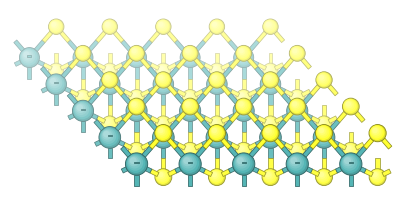

ia.draw(ax, sheet, view="z", rotate="-55x", depth_cue=True, depth_fade=0.6, depth_shrink=0.12, shading="soft")


interactive(children=(Checkbox(value=True, description='depth_cue'), FloatSlider(value=0.6, description='depth…

In [5]:
sheet = mx2("MoS2", size=(5, 5, 1), vacuum=2.0)

@interact(depth_cue=True, depth_fade=(0.0, 1.0, 0.05), depth_shrink=(0.0, 0.4, 0.02), tilt=(0, 85, 5))
def show(depth_cue=True, depth_fade=0.6, depth_shrink=0.12, tilt=55):
    fig, ax = plt.subplots(figsize=(4.5, 3.2))
    ia.draw(ax, sheet, view="z", rotate=f"-{tilt}x", depth_cue=depth_cue,
            depth_fade=depth_fade, depth_shrink=depth_shrink, shading="soft")
    plt.show()
    print_call("ia.draw", "ax", "sheet", view="z", rotate=f"-{tilt}x", depth_cue=depth_cue,
               depth_fade=depth_fade if depth_cue else None, depth_shrink=depth_shrink if depth_cue else None,
               shading="soft")

**Try it yourself:** set the tilt to 0 (a top view). Why does the depth fade make the
bottom layer of S paler?

## 5. Pointing things out: highlights, labels and measurements

* **`highlight=[ids]`** draws chosen atoms at full strength with a heavier outline (never
  faded), or `highlight={id: "red"}` to recolour them.
* **`labels="symbol"`** (or `"id"`) writes on the atoms.
* **`ia.measure(art, [i, j])`** draws a distance; three atoms give an angle, four a dihedral.

Every atom has an **id** (its index, starting at 0). Turn on the id labels to find the
numbers, then pick atoms with the sliders.

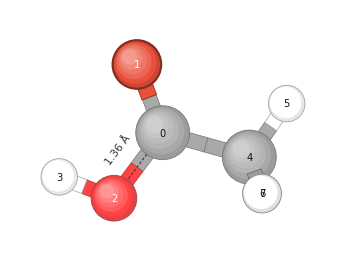

art = ia.draw(ax, acid, view="auto", shading="soft", highlight={1: "#e8503a"}, labels="id")
ia.measure(art, [0, 2])


interactive(children=(Checkbox(value=True, description='show_ids'), IntSlider(value=1, description='highlight_…

In [6]:
acid = molecule("CH3COOH")

@interact(show_ids=True, highlight_atom=(0, len(acid) - 1), atom_i=(0, len(acid) - 1), atom_j=(0, len(acid) - 1))
def show(show_ids=True, highlight_atom=1, atom_i=0, atom_j=2):
    fig, ax = plt.subplots(figsize=(3.8, 3.4))
    art = ia.draw(ax, acid, view="auto", shading="soft", highlight={highlight_atom: "#e8503a"},
                  labels="id" if show_ids else None)
    if atom_i != atom_j:
        ia.measure(art, [atom_i, atom_j])
    plt.show()
    print_call("art = ia.draw", "ax", "acid", view="auto", shading="soft", highlight={highlight_atom: "#e8503a"},
               labels="id" if show_ids else None)
    if atom_i != atom_j:
        print_call("ia.measure", "art", f"[{atom_i}, {atom_j}]")

The object `ia.draw` returns (here called `art`) knows where every atom landed, so normal
matplotlib annotation works too:

```python
ax.annotate("acid group", xy=art.xy(1), xytext=(2, 2), arrowprops={"arrowstyle": "->"})
```

**Try it yourself:** measure the O=C–O angle by passing three ids: `ia.measure(art, [1, 0, 2])`.

## 6. Molecules: bond orders and SMILES

`bond_orders=True` draws double and triple bonds. For molecules from ASE they are guessed from
bond lengths. If [RDKit](https://www.rdkit.org) is installed, `ia.from_smiles("...")` builds a 3D
molecule from a SMILES string and keeps RDKit's exact bond orders. Type any SMILES in the box.

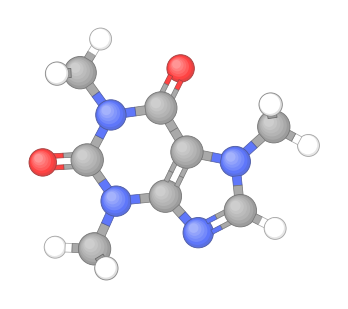

mol = ia.from_smiles("Cn1cnc2c1c(=O)n(C)c(=O)n2C")
ia.draw(ax, mol, view="auto", bond_orders=True, shading="soft")


interactive(children=(Dropdown(description='example', options=('caffeine', 'aspirin', 'acrylonitrile', 'parace…

In [7]:
examples = {"caffeine": "Cn1cnc2c1c(=O)n(C)c(=O)n2C", "aspirin": "CC(=O)Oc1ccccc1C(=O)O",
            "acrylonitrile": "C=CC#N", "paracetamol": "CC(=O)Nc1ccc(O)cc1"}

@interact(example=list(examples), your_smiles="", bond_orders=True, rings=False)
def show(example="caffeine", your_smiles="", bond_orders=True, rings=False):
    smiles = your_smiles.strip() or examples[example]
    try:
        mol = ia.from_smiles(smiles)
    except Exception as err:          # RDKit missing, or a SMILES it cannot read
        print("Could not build", repr(smiles), "->", err)
        return
    fig, ax = plt.subplots(figsize=(4, 3.4))
    ia.draw(ax, mol, view="auto", bond_orders=bond_orders, shading="soft",
            rings={"aromatic": "auto"} if rings else None)
    plt.show()
    print_call("mol = ia.from_smiles", f'"{smiles}"')
    print_call("ia.draw", "ax", "mol", view="auto", bond_orders=bond_orders, shading="soft",
               rings={"aromatic": "auto"} if rings else None)

## 7. Crystals: unit cells, polyhedra and planes

For crystals (anything with a unit cell) you can add:

* **`cell=True`**: the unit-cell outline,
* **`polyhedra={"centers": "Ti"}`**: coordination polyhedra around chosen atoms,
* **`boundary=True`**: repeat atoms sitting on cell faces and corners, as VESTA does,
* **`planes=[(1, 1, 1)]`**: lattice planes, and **`cell_vectors=True`**: labelled a, b, c arrows.

`ia.select.tile(crystal, (2, 2, 2))` repeats the cell.

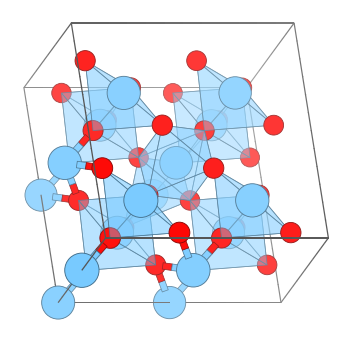

ia.draw(ax, select.tile(rutile, (2, 2, 2), centred=False), view="z", rotate="-25x,20y", style="vesta", cell=True, boundary=False, polyhedra={"centers": "Ti"}, pbc_bonds=False)


interactive(children=(Dropdown(description='structure', options=('rutile TiO2 (2x2x2)', 'rock salt NaCl'), val…

In [8]:
from ase.spacegroup import crystal
from inkatoms import select

rutile = crystal(["Ti", "O"], basis=[(0, 0, 0), (0.3, 0.3, 0)], spacegroup=136,
                 cellpar=[4.59, 4.59, 2.96, 90, 90, 90])
rocksalt = bulk("NaCl", "rocksalt", a=5.64, cubic=True)

@interact(structure=["rutile TiO2 (2x2x2)", "rock salt NaCl"], polyhedra=True, cell=True,
          boundary=False, plane_111=False, tilt=(0, 60, 5), spin=(0, 60, 5))
def show(structure="rutile TiO2 (2x2x2)", polyhedra=True, cell=True, boundary=False, plane_111=False,
         tilt=25, spin=20):
    if structure.startswith("rutile"):
        atoms, centre, name = select.tile(rutile, (2, 2, 2), centred=False), "Ti", "select.tile(rutile, (2, 2, 2), centred=False)"
    else:
        atoms, centre, name = rocksalt, "Na", "rocksalt"
    fig, ax = plt.subplots(figsize=(4, 3.8))
    ia.draw(ax, atoms, view="z", rotate=f"-{tilt}x,{spin}y", style="vesta", cell=cell, boundary=boundary,
            polyhedra={"centers": centre} if polyhedra else None, pbc_bonds=False,
            planes=[(1, 1, 1)] if plane_111 else None)
    plt.show()
    print_call("ia.draw", "ax", name, view="z", rotate=f"-{tilt}x,{spin}y", style="vesta", cell=cell,
               boundary=boundary, polyhedra={"centers": centre} if polyhedra else None, pbc_bonds=False,
               planes=[(1, 1, 1)] if plane_111 else None)

## 8. Colouring atoms by a value

`color_by=` colours atoms by any per-atom number instead of their element: height (`"z"`),
number of neighbours (`"coordination"`), or your own array of charges, energies, forces and so
on. `ia.colorbar(art)` adds the scale. `vectors=` draws an arrow on each atom, for example forces.

`cutoffs={"Pt-Pt": 3.0}` sets which distances count as a bond (in Å). With it, colouring by
coordination shows the surface atoms (9 neighbours) apart from the ones inside (12).

In [9]:
#@title Make a Pt(111) slab with CO on top, and made-up per-atom charges
slab = fcc111("Pt", size=(4, 4, 3), vacuum=6.0)
add_adsorbate(slab, molecule("CO"), 1.9, "ontop")
rng = np.random.default_rng(0)
fake_charges = rng.normal(0, 0.3, len(slab))          # stand-in for your own per-atom data

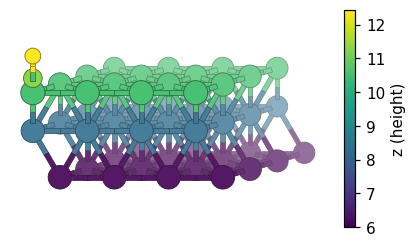

art = ia.draw(ax, slab, view="-y", rotate="10x", color_by="z", cmap="viridis", cutoffs={"Pt-Pt": 3.0}, pbc_bonds=False)
ia.colorbar(art, label="z (height)")


interactive(children=(Dropdown(description='colour_by', options=('z (height)', 'coordination', 'my own array')…

In [10]:
@interact(colour_by=["z (height)", "coordination", "my own array"], cmap=["viridis", "cividis", "magma", "RdBu_r"],
          side_view=True)
def show(colour_by="z (height)", cmap="viridis", side_view=True):
    value = {"z (height)": "z", "coordination": "coordination", "my own array": fake_charges}[colour_by]
    fig, ax = plt.subplots(figsize=(4.6, 3.2))
    art = ia.draw(ax, slab, view="-y" if side_view else "z", rotate="10x" if side_view else None,
                  color_by=value, cmap=cmap, cutoffs={"Pt-Pt": 3.0}, pbc_bonds=False)
    ia.colorbar(art, label=colour_by)
    plt.show()
    print_call("art = ia.draw", "ax", "slab", view="-y" if side_view else "z", rotate="10x" if side_view else None,
               color_by=raw("fake_charges") if colour_by == "my own array" else value, cmap=cmap,
               cutoffs={"Pt-Pt": 3.0}, pbc_bonds=False)
    print_call("ia.colorbar", "art", label=colour_by)

## 9. Surfaces: cutting out the part you want

Real simulation cells are big and busy. `inkatoms.select` cuts out the part a figure is about:

* `select.slab(atoms, axis="y", half_width=4, at=[site])` keeps a thin slice through a site,
* `select.around(atoms, at=[site], radius=6)` keeps a sphere,
* `select.tile(...)` repeats a periodic cell first, so bonds across the cell edge stay whole.

Atom **ids survive every cut**, so `highlight` still finds the same atom afterwards.

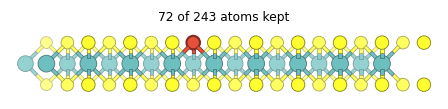

part = select.slab(big, axis="y", half_width=3.5, at=[4], keep=[4])
ia.draw(ax, part, view="-y", highlight={4: "#e8503a"}, depth_cue=True)


interactive(children=(Dropdown(description='cut', options=('thin slab', 'sphere'), value='thin slab'), FloatSl…

In [11]:
big = select.tile(mx2("MoS2", size=(3, 3, 1), vacuum=4.0), (3, 3, 1))
site = 4                                     # an S atom of the original cell

@interact(cut=["thin slab", "sphere"], size=(2.0, 8.0, 0.5), depth_cue=True)
def show(cut="thin slab", size=3.5, depth_cue=True):
    if cut == "thin slab":
        part = select.slab(big, axis="y", half_width=size, at=[site], keep=[site])
    else:
        part = select.around(big, at=[site], radius=2 * size, keep=[site])
    fig, ax = plt.subplots(figsize=(5, 2.6))
    art = ia.draw(ax, part, view="-y", highlight={site: "#e8503a"}, depth_cue=depth_cue)
    ax.set_title(f"{len(part)} of {len(big)} atoms kept", fontsize=8)
    plt.show()
    if cut == "thin slab":
        print_call("part = select.slab", "big", axis="y", half_width=size, at=[site], keep=[site])
    else:
        print_call("part = select.around", "big", at=[site], radius=2 * size, keep=[site])
    print_call("ia.draw", "ax", "part", view="-y", highlight={site: "#e8503a"}, depth_cue=depth_cue)

## 10. Building a figure for a paper

A few helpers for figures that will be printed:

* **`ia.figsize("rsc", "double", 0.4)`**: the figure size in inches for a journal column
  (`"acs"`, `"rsc"`, `"nature"`, `"elsevier"`, `"aip"`, `"aps"`; `"single"` or `"double"`).
* **`scale=0.25`**: fix the scale to 0.25 inches per Å, so every panel and figure in a paper
  shows structures at the same size.
* **`ia.legend(ax, art)`** and **`ia.scale_bar(ax, 2)`**: an element key and a 2 Å bar.
* **`ia.inset(ax, atoms, (x, y))`**: a small structure at a point of a normal plot.

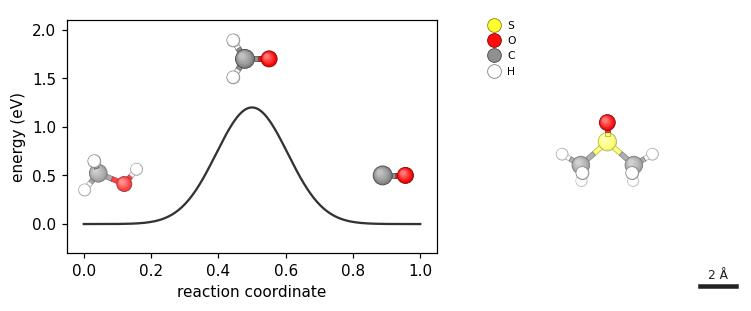

In [12]:
fig = plt.figure(figsize=ia.figsize("rsc", "double", 0.42))
ax_plot = fig.add_axes([0.07, 0.17, 0.5, 0.75])
x = np.linspace(0, 1, 200)
energy = 1.2 * np.exp(-((x - 0.5) / 0.15) ** 2)
ax_plot.plot(x, energy, color="#333333")
ax_plot.set(xlabel="reaction coordinate", ylabel="energy (eV)", ylim=(-0.3, 2.1))
for xi, name in ((0.08, "CH3OH"), (0.5, "H2CO"), (0.92, "CO")):
    ia.inset(ax_plot, molecule(name), (xi, np.interp(xi, x, energy) + 0.5), size=(0.2, 0.35),
             view="auto", shading="soft", scale=0.18)

ax_mol = fig.add_axes([0.62, 0.05, 0.36, 0.9])
art = ia.draw(ax_mol, molecule("C2H6SO"), view="auto", rotate="20x", shading="soft", scale=0.18)
ia.legend(ax_mol, art, loc="upper left", fontsize=7)
ia.scale_bar(ax_mol, 2, loc="lower right")
plt.show()

**Try it yourself:** change `"rsc"` to `"acs"` and `"double"` to `"single"`, and notice that
the molecules stay the same size because the scale is fixed.

## 11. Trajectories: finding and drawing reactions

Given a simulation trajectory (a list of frames) whose atoms keep an id (`"uid"`),
inkatoms can find **bonds that form and break** and draw each step. A change only counts once it
has lasted `min_frames` frames, so vibrations across a bond cutoff are not mistaken for chemistry.

We make a small pretend trajectory here: an H₂S that loses an H, then an SH drifting off
a surface S. With real data you would use `frames = ase.io.read("md.xyz", ":")`.

In [13]:
#@title Make a pretend 60-frame trajectory
rng = np.random.default_rng(0)
frames = []
for f in range(60):
    h_out = [0.96 + (0.06 * (f - 20) if f > 20 else 0), 0.93, 0]        # this H leaves after frame 20
    lift = [0, 0, 0.12 * max(f - 40, 0)]                                # the SH lifts off after frame 40
    pos = np.array([[0, 0, 0], h_out, [-0.96, 0.93, 0], [0, -2.3, 0], [2.3, -2.3, 0]], float)
    pos[[0, 2]] += lift
    pos += rng.normal(0, 0.02, pos.shape)                               # a little thermal jitter
    frame = Atoms("SHHSS", positions=pos)
    frame.new_array("uid", np.arange(5))
    frame.info["time_ps"] = 0.1 * f
    frames.append(frame)

In [14]:
cutoffs = {"S-H": 1.6, "S-S": 2.45}
reaction = ia.find_reactions(frames, cutoffs=cutoffs, min_frames=4)[0]
print(reaction)

`event_strip` draws the reaction: one panel before it, then one per step, with the atoms
involved in strong colours and the bond that just broke dashed.

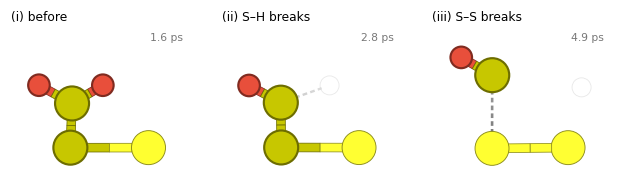

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(7, 2.6))
ia.event_strip(axes, frames, reaction, cutoffs=cutoffs, view="z", rotate="-55x", crop="around", around=6)
plt.show()

**Trails** show where atoms went. Pick a style: `"arrow"` (a smoothed route), `"ghosts"`
(faded copies at earlier times) or `"line"` (every step). `ia.plot_neighbours` turns what
happened to one atom into a simple timeline.

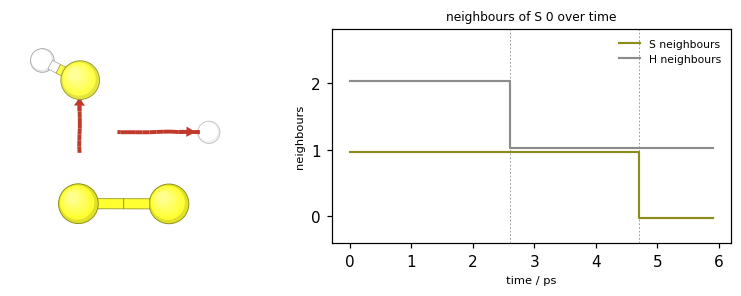

ia.draw(ax1, frames[-1], view="z", rotate="-55x", cutoffs=cutoffs, shading="soft", trails={"frames": frames, "ids": [0, 1], "style": "arrow", "color": "#c0392b"})
ia.plot_neighbours(ax2, frames, 0, cutoffs=cutoffs, events=reaction.events, min_frames=4)


interactive(children=(Dropdown(description='style', options=('arrow', 'ghosts', 'line'), value='arrow'), Dropd…

In [16]:
@interact(style=["arrow", "ghosts", "line"], which=["the leaving H", "the S that lifts off", "both"])
def show(style="arrow", which="both"):
    ids = {"the leaving H": [1], "the S that lifts off": [0], "both": [0, 1]}[which]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7.2, 2.8), gridspec_kw={"width_ratios": [1, 1.3]})
    ia.draw(ax1, frames[-1], view="z", rotate="-55x", cutoffs=cutoffs, shading="soft",
            trails={"frames": frames, "ids": ids, "style": style, "color": "#c0392b"})
    ia.plot_neighbours(ax2, frames, 0, cutoffs=cutoffs, events=reaction.events, min_frames=4)
    ax2.set_title("neighbours of S 0 over time", fontsize=8)
    plt.tight_layout()
    plt.show()
    print_call("ia.draw", "ax1", "frames[-1]", view="z", rotate="-55x", cutoffs=raw("cutoffs"), shading="soft",
               trails={"frames": raw("frames"), "ids": ids, "style": style, "color": "#c0392b"})
    print_call("ia.plot_neighbours", "ax2", "frames", "0", cutoffs=raw("cutoffs"), events=raw("reaction.events"),
               min_frames=4)

## 12. Comparing two structures

`ia.draw_comparison(ax, before, after)` draws the second structure over faint "ghosts" of the
first, colours atoms by how far they moved and adds arrows. It matches the atoms (by id when
they share ids, otherwise by position) and removes any overall rotation first.

Below: a small copper cluster, shaken a little, then relaxed with a simple force field.

In [17]:
#@title Make a before/after pair: a shaken Cu cluster, then relaxed with EMT
from ase.calculators.emt import EMT
from ase.cluster import Icosahedron
from ase.optimize import BFGS

cluster = Icosahedron("Cu", 3)
cluster.rattle(0.2, seed=1)
before = cluster.copy()
cluster.calc = EMT()
BFGS(cluster, logfile=None).run(fmax=0.05)
after = cluster

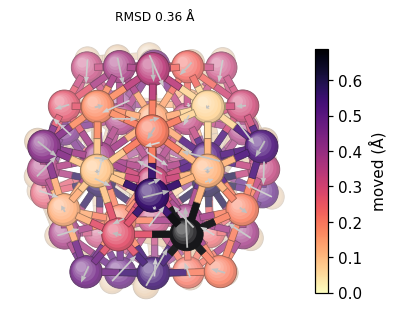

art, comparison = ia.draw_comparison(ax, before, after, view="z", rotate="-20x", shading="soft", arrow_scale=3.0, min_shift=0.05)


interactive(children=(FloatSlider(value=3.0, description='arrow_scale', max=10.0, min=1.0, step=0.5), FloatSli…

In [18]:
@interact(arrow_scale=(1.0, 10.0, 0.5), min_shift=(0.0, 0.3, 0.02))
def show(arrow_scale=3.0, min_shift=0.05):
    fig, ax = plt.subplots(figsize=(4.2, 3.6))
    art, comparison = ia.draw_comparison(ax, before, after, view="z", rotate="-20x", shading="soft",
                                         arrow_scale=arrow_scale, min_shift=min_shift)
    ia.colorbar(art, label="moved (Å)")
    ax.set_title(f"RMSD {comparison.rmsd:.2f} Å", fontsize=8)
    plt.show()
    print_call("art, comparison = ia.draw_comparison", "ax", "before", "after", view="z", rotate="-20x",
               shading="soft", arrow_scale=arrow_scale, min_shift=min_shift)

If you know some atom correspondences yourself, you can say so:
`ia.compare(a, b, known={12: 40})` fixes those pairs, and `pairs=[...]` gives the whole mapping.

## 13. Saving, and using your own files

**Saving.** Save as PDF or SVG to keep the vector drawing:

```python
fig.savefig("my_figure.pdf")
fig.savefig("my_figure.svg")
```

With `ia.draw(..., editable=True)` every atom and bond becomes its own named object in the SVG
(for example `atom-12`), which is handy for touching up in Illustrator or Inkscape.

**Your own structures.** ASE reads almost any format (xyz, extxyz, cif, POSCAR, cube, ...):

```python
from ase.io import read
atoms = read("my_structure.cif")          # one structure
frames = read("my_md.xyz", ":")           # every frame of a trajectory
```

pymatgen structures, RDKit molecules and MDAnalysis universes also work directly with `ia.draw`.

**From the terminal**, without writing any code:

```bash
inkatoms my_structure.cif -o picture.pdf --view z --polyhedra --cell --style vesta
```

## Cheat sheet

| I want to... | use |
|---|---|
| draw a structure | `ia.draw(ax, atoms)` |
| change the view | `view="z"`, `"-y"`, `"auto"`, `rotate="20x,-30y"` |
| change the look | `style="cpk"`, `shading="soft"`, `mode="spacefill"`, `colors={"S": "gold"}` |
| turn off depth fading | `depth_cue=False` |
| point at atoms | `highlight=[3, 7]`, `labels="id"`, `ia.measure(art, [3, 7])` |
| double bonds | `bond_orders=True` |
| crystals | `cell=True`, `polyhedra={"centers": "Ti"}`, `boundary=True` |
| colour by a value | `color_by="z"`, then `ia.colorbar(art)` |
| cut out a region | `select.slab(...)`, `select.around(...)`, `select.tile(...)` |
| fixed size across figures | `scale=0.25` (inches per Å) |
| reactions in a trajectory | `ia.find_reactions(frames)`, `ia.event_strip(axes, frames, reaction)` |
| where atoms went | `trails={"frames": frames, "ids": [...], "style": "arrow"}` |
| before vs after | `ia.draw_comparison(ax, before, after)` |

For every option of a function, run `help(ia.draw)` (or any other function) in a cell.
Questions, bugs and ideas: https://github.com/JoelCrewe/InkAtoms/issues

In [19]:
help(ia.draw)